## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Importing Libraries](#0)<br>
2.  [Downloading and Importing Data](#2)<br>
3.  [Visualizing Data using Matplotlib](#4) <br>
4.  [Pie Charts](#6) <br>
5.  [Box Plots](#8) <br>
6.  [Scatter Plots](#10) <br>
7.  [Bubble Plots](#12) <br>

</div>


# Importing Libraries<a id="0"></a>


In [1]:
# Import modul utama
# Import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np  # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd  # pustaka struktur data utama

mpl.style.use("ggplot")  # tema plot dengan gaya ggplot

# Periksa versi Matplotlib terbaru
print("Versi Matplotlib:", mpl.__version__)

Versi Matplotlib: 3.11.2


## Importing Data <a id="2"></a>
Dataset: Imigrasi ke Kanada dari tahun 1980 hingga 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's 

Dalam lab ini, data yang digunakan akn berfokus pada Imigrasi Kanada dan menggunakan **dataset yang sudah dibersihkan** dan dapat diunduh dari <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">disini</a>.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk penyegaran cepat keterampilan Pandas, melalui [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [2]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")
print("Data sudah dibaca ke dalam dataframe pandas")

Data sudah dibaca ke dalam dataframe pandas


In [3]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Cari tahu berapa banyak entri yang ada dalam dataset.

In [4]:
df_canada.shape

(195, 39)

# Visualizing Data using Matplotlib<a id="4"></a>

Untuk memudahkan pembuatan grafik data, pertama-tama tetapkan nama negara (`Country`) sebagai indeks, ini berguna untuk mencari negara dengan cepat menggunakan metode `.loc`.

In [5]:
df_canada.set_index("Country", inplace=True)

In [6]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Perhatikan bahwa nama-nama negara sekarang berfungsi sebagai indeks.

In [7]:
print("data dimensions:", df_canada.shape)

data dimensions: (195, 38)


Terakhir, buat daftar tahun dari 1980 - 2013, ini akan berguna saat mulai membuat grafik data.

In [8]:
years = list(map(str, range(1980, 2014)))

# Pie Charts <a id="6"></a>

Pie chart atau diagram lingkaran adalah grafik melingkar yang menampilkan proporsi numerik dengan membagi lingkaran (atau pai) menjadi irisan-irisan yang proporsional. Anda mungkin sudah familiar dengan diagram lingkaran karena banyak digunakan dalam bisnis dan media. Kita dapat membuat diagram lingkaran di Matplotlib dengan memberikan kata kunci `kind=pie`.

Mari kita gunakan diagram lingkaran untuk mengeksplorasi proporsi (persentase) imigran baru yang dikelompokkan menurut benua untuk seluruh periode waktu dari tahun 1980 hingga 2013.


Langkah 1: Kumpulkan data.

Kita akan menggunakan metode `groupby` dari *pandas* untuk meringkas data imigrasi berdasarkan `Continent`. Proses umum dari `groupby` melibatkan langkah-langkah berikut:

1.  **Split:** Membagi data ke dalam beberapa kelompok berdasarkan kriteria tertentu.
2.  **Apply:** Menerapkan fungsi pada setiap kelompok secara independen:
    .sum()
    .count()
    .mean()
    .std()
    .aggregate()
    .apply()
    .etc..
3.  **Combine:** Menggabungkan hasil-hasil tersebut ke dalam sebuah struktur data.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig4SplitApplyCombine.png" height="400" align="center">


In [9]:
# kelompokkan negara berdasarkan benua dan terapkan fungsi sum()
df_continents = df_canada.groupby("Continent").sum()

In [10]:
# Catatan: output dari metode groupby adalah objek `groupby`.
# Kita tidak dapat menggunakannya lebih lanjut sampai kita menerapkan sebuah fungsi (misalnya .sum())

print(type(df_canada.groupby("Continent")))

<class 'pandas.api.typing.DataFrameGroupBy'>


In [11]:
df_continents.head()

,Region,DevName,1980,1981,1982,1983,1984,1985,1986,1987,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Continent,,,,,,,,,,,,,,,,,,,,,
Africa,Northern AfricaMiddle AfricaWestern AfricaSout...,Developing regionsDeveloping regionsDeveloping...,3951,4363,3819,2671,2639,2650,3782,7494,...,27523,29188,28284,29890,34534,40892,35441,38083,38543,618948
Asia,Southern AsiaWestern AsiaWestern AsiaWestern A...,Developing regionsDeveloping regionsDeveloping...,31025,34314,30214,24696,27274,23850,28739,43203,...,159253,149054,133459,139894,141434,163845,146894,152218,155075,3317794
Europe,Southern EuropeSouthern EuropeWestern EuropeEa...,Developed regionsDeveloped regionsDeveloped re...,39760,44802,42720,24638,22287,20844,24370,46698,...,35955,33053,33495,34692,35078,33425,26778,29177,28691,1410947
Latin America and the Caribbean,CaribbeanSouth AmericaCaribbeanCaribbeanCentra...,Developing regionsDeveloping regionsDeveloping...,13081,15215,16769,15427,13678,15171,21179,28471,...,24747,24676,26011,26547,26867,28818,27856,27173,24950,765148
Northern America,Northern AmericaNorthern America,Developed regionsDeveloped regions,9378,10030,9074,7100,6661,6543,7074,7705,...,8394,9613,9463,10190,8995,8142,7677,7892,8503,241142


Langkah 2: Plot data. Kita akan memasukkan kata kunci `kind = 'pie'`, beserta parameter tambahan berikut:

*   `autopct` -  adalah string atau fungsi yang digunakan untuk memberi label pada irisan dengan nilai numeriknya. Label akan ditempatkan di dalam irisan. Jika berupa string format, label akan menjadi `fmt%pct`.
*   `startangle` - Memutar titik awal diagram lingkaran sebesar sudut derajat berlawanan arah jarum jam dari sumbu x.
*   `shadow` - Menggambar bayangan di bawah pai (untuk memberikan kesan 3D).


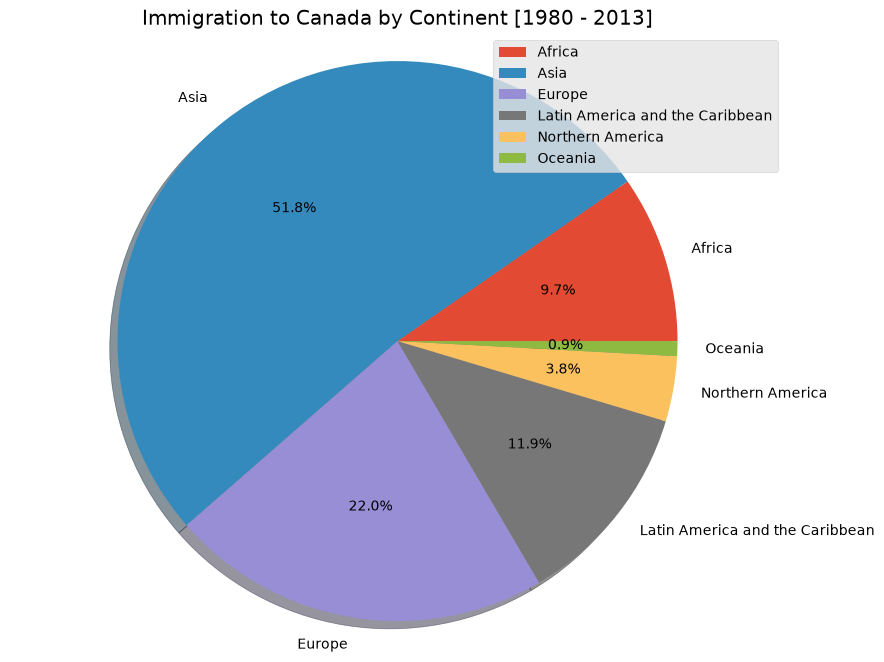

In [16]:
# autopct create %, start angle represent starting point
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 8),
    autopct="%1.1f%%",  # tambahkan dalam persentase
    shadow=True,
)

plt.title("Immigration to Canada by Continent [1980 - 2013]")
plt.axis(
    "equal"
)  # Mengatur tampilan diagram lingkaran agar menyerupai bentuk lingkaran.
plt.legend(labels=df_continents.index, loc="upper right")

plt.savefig("../outputs/pie_chart_without_explode.png", dpi=200, bbox_inches="tight")
plt.show()

Visual di atas kurang jelas, angka dan teks tumpang tindih di beberapa bagian. Mari kita lakukan beberapa modifikasi untuk meningkatkan visualnya:

*   Hapus label teks pada diagram lingkaran dengan memberikan parameter `legend` dan tambahkan sebagai legenda terpisah menggunakan `plt.legend()`.
*   Geser persentase agar berada tepat di luar diagram lingkaran dengan memberikan parameter `pctdistance`.
*   Masukkan serangkaian warna khusus untuk benua dengan memberikan parameter `colors`.
*   **Explode** diagram lingkaran tersebut digunakan untuk menekankan tiga benua terendah (Afrika, Amerika Utara, dan Amerika Latin serta Karibia) dengan memasukkan parameter `explode`


In [13]:
color_list = ["gold", "yellowgreen", "lightcoral", "lightskyblue", "lightgreen", "pink"]
explode_list = [
    0.1,
    0,
    0,
    0,
    0.1,
    0.1,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

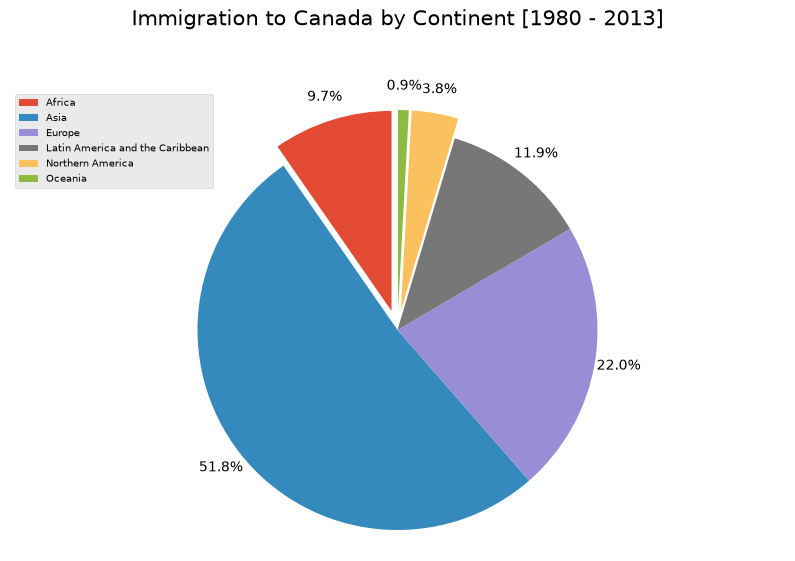

In [14]:
# Buat plot
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,  # matikan label pada diagram lingkaran
    pctdistance=1.12,  # rasio antara pusat setiap irisan pai dan awal teks yang dihasilkan oleh autopct
    color=color_list,  # tambahkan warna khusus
    explode=explode_list,  # 'explode' di 3 benua terendah
)

# Perbesar ukuran judul sebesar 12% agar sesuai dengan pctdistance.
plt.title("Immigration to Canada by Continent [1980 - 2013]", y=1.12, fontsize=15)

plt.axis("equal")

# tambahkan legenda
plt.legend(labels=df_continents.index, loc="upper left", fontsize=7)

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent.png", dpi=200, bbox_inches="tight"
)
plt.show()

**Pertanyaan:** Dengan menggunakan diagram lingkaran, jelaskan proporsi (persentase) imigran baru yang dikelompokkan berdasarkan benua pada tahun 2013.

**Catatan**: Anda mungkin perlu bereksperimen dengan nilai eksplorasi untuk memperbaiki nilai irisan yang tumpang tindih.


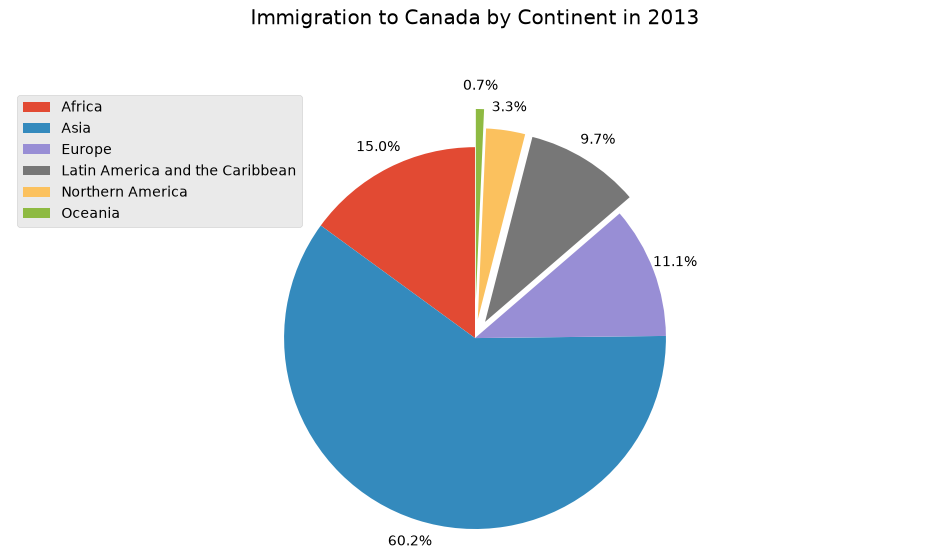

In [15]:
explode_list2 = [
    0.0,
    0,
    0,
    0.1,
    0.1,
    0.2,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

# Buat plot
df_continents["2013"].plot(
    kind="pie",
    figsize=(12, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,
    pctdistance=1.12,
    explode=explode_list2,
)

plt.title("Immigration to Canada by Continent in 2013", y=1.12)
plt.axis("equal")

plt.legend(labels=df_continents.index, loc="upper left")

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent_2013.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()